# PA3 - Classificação de Fauna com Poucos Rótulos (Trilha C: Professor e Aluno)

Este notebook consolida todo o experimento do **Projeto Aplicado 3 (ENA24-detection)** seguindo estritamente a **Trilha C (Destilação Professor $\rightarrow$ Aluno)** e todas as regras de higiene de *splits*:

- **`train` (6.505 imagens):** *pool* não rotulado, exceto os subconjuntos aninhados e balanceados de $K \in \{1, 5, 20\}$ rótulos por classe (`21`, `105` e `420` imagens humanas).
- **`val` (202 imagens):** utilizado exclusivamente para seleção de épocas, hiperparâmetros e escolha do melhor checkpoint do aluno (`checkpoints/best_student.pth`). **O professor BioCLIP nunca toca o `val`.**
- **`test_public` (811 imagens):** utilizado apenas para reporte das métricas finais (F1 Macro e Acurácia), diagnóstico zero-shot do professor e galeria Grad-CAM da Parte 3.
- **Restrição do entregável (`predict.py`):** modelo aluno `ResNet-18` com **11.187.285 parâmetros** ($\le 12\text{M}$), rodando em **CPU** e **100% offline** (o professor ViT-B/16 nunca entra em produção).

In [1]:
import json
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader
from IPython.display import Image as IPyImage, display

if not os.path.isdir("src") and os.path.isdir("../src"):
    os.chdir("..")

sys.path.insert(0, os.path.abspath("."))

from src.dataset import (
    ENA24Dataset,
    get_transforms,
    is_infrared_image,
    list_image_ids_in_dir,
    load_class_mapping,
    load_split_df,
)
from src.metrics import (
    compute_macro_f1_and_accuracy,
    compute_ood_scores,
    compute_per_class_f1,
)
from src.models import MAX_ALLOWED_PARAMS, count_parameters, evaluate_model, load_student_checkpoint
from src.teacher import load_teacher_cache

DATA_DIR = "data" if os.path.isdir("data/images") else "data/pa3_dados"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Diretório de trabalho: {os.getcwd()} | DATA_DIR={DATA_DIR} | DEVICE={DEVICE}")

Diretório de trabalho: /home/rique/Documents/fgv/6o/DL/assignments/dl-pa3-2026 | DATA_DIR=data | DEVICE=cuda


---
## 1. Análise Exploratória dos Dados (EDA)

Verificamos o mapeamento das **21 espécies**, os três orçamentos de rótulos humanos (`rotulos_1/5/20.csv`), o desbalanceamento natural das câmeras trap em `val` e `test_public`, e a proporção de capturas noturnas em **infravermelho (IR monocromático)**.

,split,imagens,noite_ir,pct_ir
0,train,6505,3644,56.0
1,val,202,105,52.0
2,test_public,811,391,48.2


Desbalanceamento test_public: min=4 (horse), max=82 (american_black_bear), razão=20.5x
Orçamentos humanos balanceados: {1: 21, 5: 105, 20: 420}


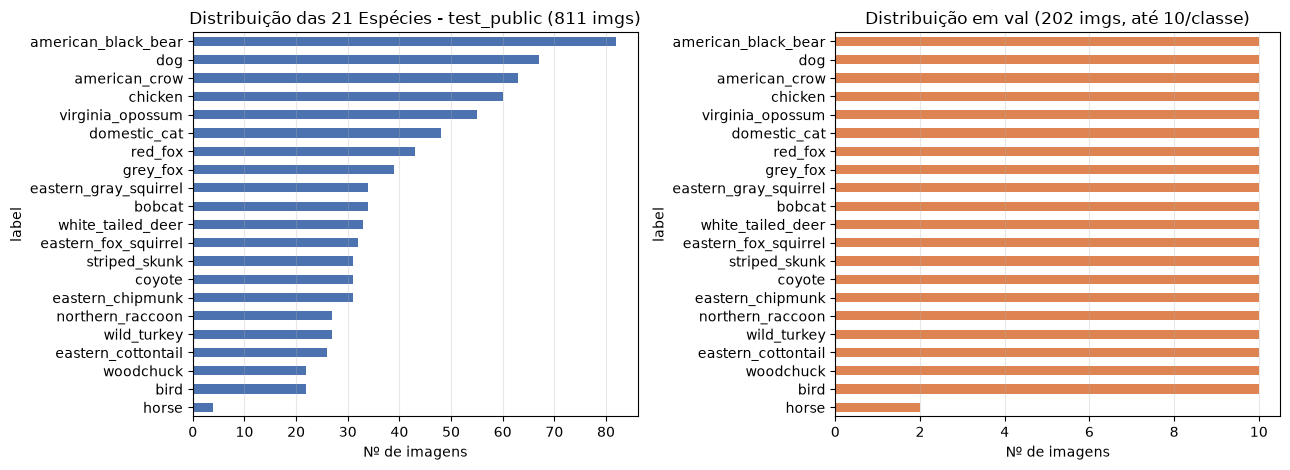

In [2]:
class_names, label_to_idx, idx_to_label = load_class_mapping(DATA_DIR)
train_ids = list_image_ids_in_dir(os.path.join(DATA_DIR, "images", "train"))
df_val = load_split_df(os.path.join(DATA_DIR, "labels", "val.csv"), label_to_idx)
df_test = load_split_df(os.path.join(DATA_DIR, "labels", "test_public.csv"), label_to_idx)

budget_dfs = {
    k: load_split_df(os.path.join(DATA_DIR, "labels", f"rotulos_{k}.csv"), label_to_idx)
    for k in (1, 5, 20)
}
# Checagem de aninhamento (rotulos_1 ⊂ rotulos_5 ⊂ rotulos_20)
assert set(budget_dfs[1]["image_id"]).issubset(set(budget_dfs[5]["image_id"]))
assert set(budget_dfs[5]["image_id"]).issubset(set(budget_dfs[20]["image_id"]))

# Estatísticas de IR nos splits usando cache ou amostragem direta das imagens
def ir_stats(split_name: str, img_ids: list[str]) -> tuple[int, int, float]:
    n_ir = 0
    for img_id in img_ids:
        path = os.path.join(DATA_DIR, "images", split_name, f"{img_id}.jpg")
        with Image.open(path) as im:
            if is_infrared_image(im):
                n_ir += 1
    return n_ir, len(img_ids), 100.0 * n_ir / max(1, len(img_ids))

ir_summary = []
for sp, ids in [
    ("train", train_ids),
    ("val", df_val["image_id"].tolist()),
    ("test_public", df_test["image_id"].tolist()),
]:
    n_ir, total, pct = ir_stats(sp, ids)
    ir_summary.append({"split": sp, "imagens": total, "noite_ir": n_ir, "pct_ir": round(pct, 1)})

display(pd.DataFrame(ir_summary))

counts_test = df_test["label"].value_counts().reindex(class_names, fill_value=0)
counts_val = df_val["label"].value_counts().reindex(class_names, fill_value=0)
print(
    f"Desbalanceamento test_public: min={counts_test.min()} ({counts_test.idxmin()}), "
    f"max={counts_test.max()} ({counts_test.idxmax()}), razão={counts_test.max() / max(1, counts_test.min()):.1f}x"
)
print("Orçamentos humanos balanceados:", {k: len(df) for k, df in budget_dfs.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
counts_test.sort_values().plot.barh(ax=axes[0], color="#4c72b0", title="Distribuição das 21 Espécies - test_public (811 imgs)")
axes[0].set_xlabel("Nº de imagens")
axes[0].grid(axis="x", alpha=0.3)

counts_val.reindex(counts_test.sort_values().index).plot.barh(ax=axes[1], color="#dd8452", title="Distribuição em val (202 imgs, até 10/classe)")
axes[1].set_xlabel("Nº de imagens")
axes[1].grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---
## 2. Parte 0 - O Piso Supervisionado e Por Que 5 Rótulos Não Bastam

Comparamos no orçamento padrão **`K=5` (`105` rótulos humanos, `seed=42`)**:
1. **Parte 0(a) - `SmallCNN` treinada do zero (`394.293` parâmetros):** sem *transfer learning*, com apenas 5 exemplos por classe, a rede extrai filtros pobres e estagna cedo.
2. **Parte 0(b) - `ResNet-18` pré-treinada na ImageNet (`11.187.285` parâmetros):** atinge representação melhor que o treino do zero, mas entra rapidamente em **memorização (overfitting)** do pequeno conjunto de treino (`train_loss -> ~0.12`, `train_f1 -> ~0.99`), enquanto `val_f1` estaciona abaixo de `0.41`.

,Modelo,Parâmetros,Época Overfit,Melhor Época (val),Val F1,Test F1 Macro,Test Acurácia
0,"SmallCNN do zero (K=5, s=42)",394293,14,27,0.2137,0.1978,0.2084
1,"Piso ResNet-18 (K=5, s=42)",11187285,13,33,0.3999,0.4480,0.4772


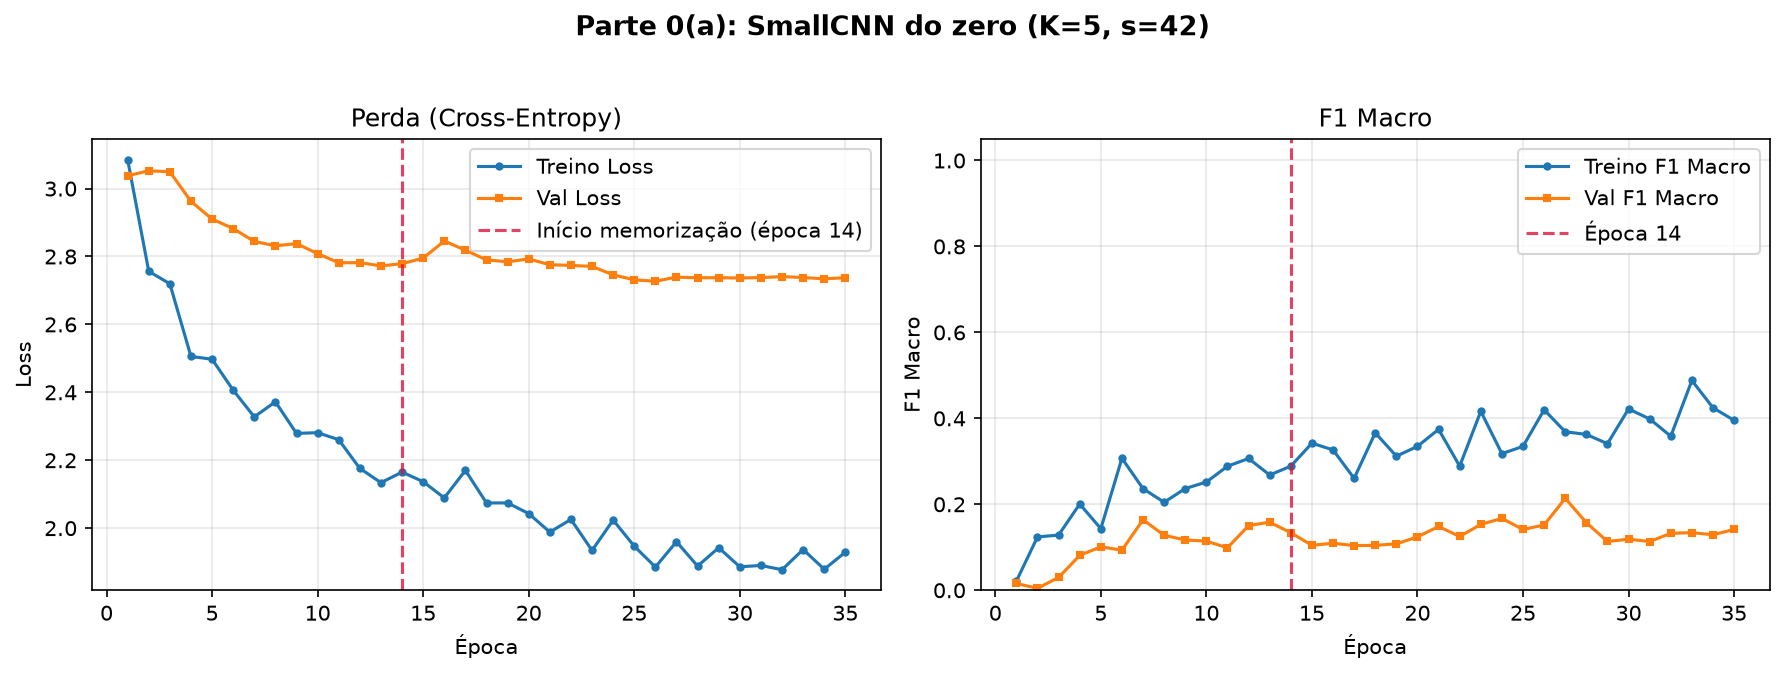

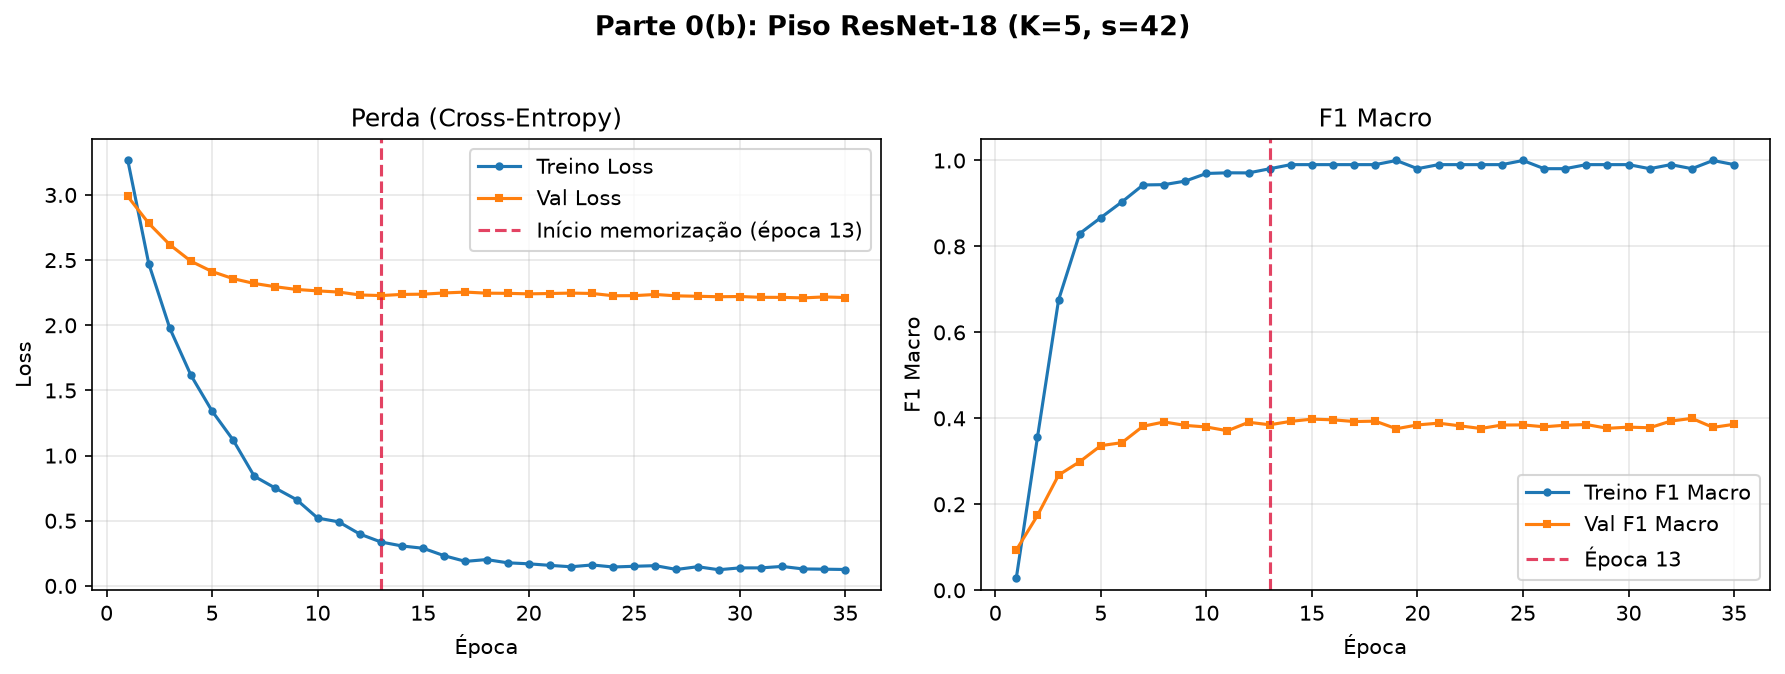

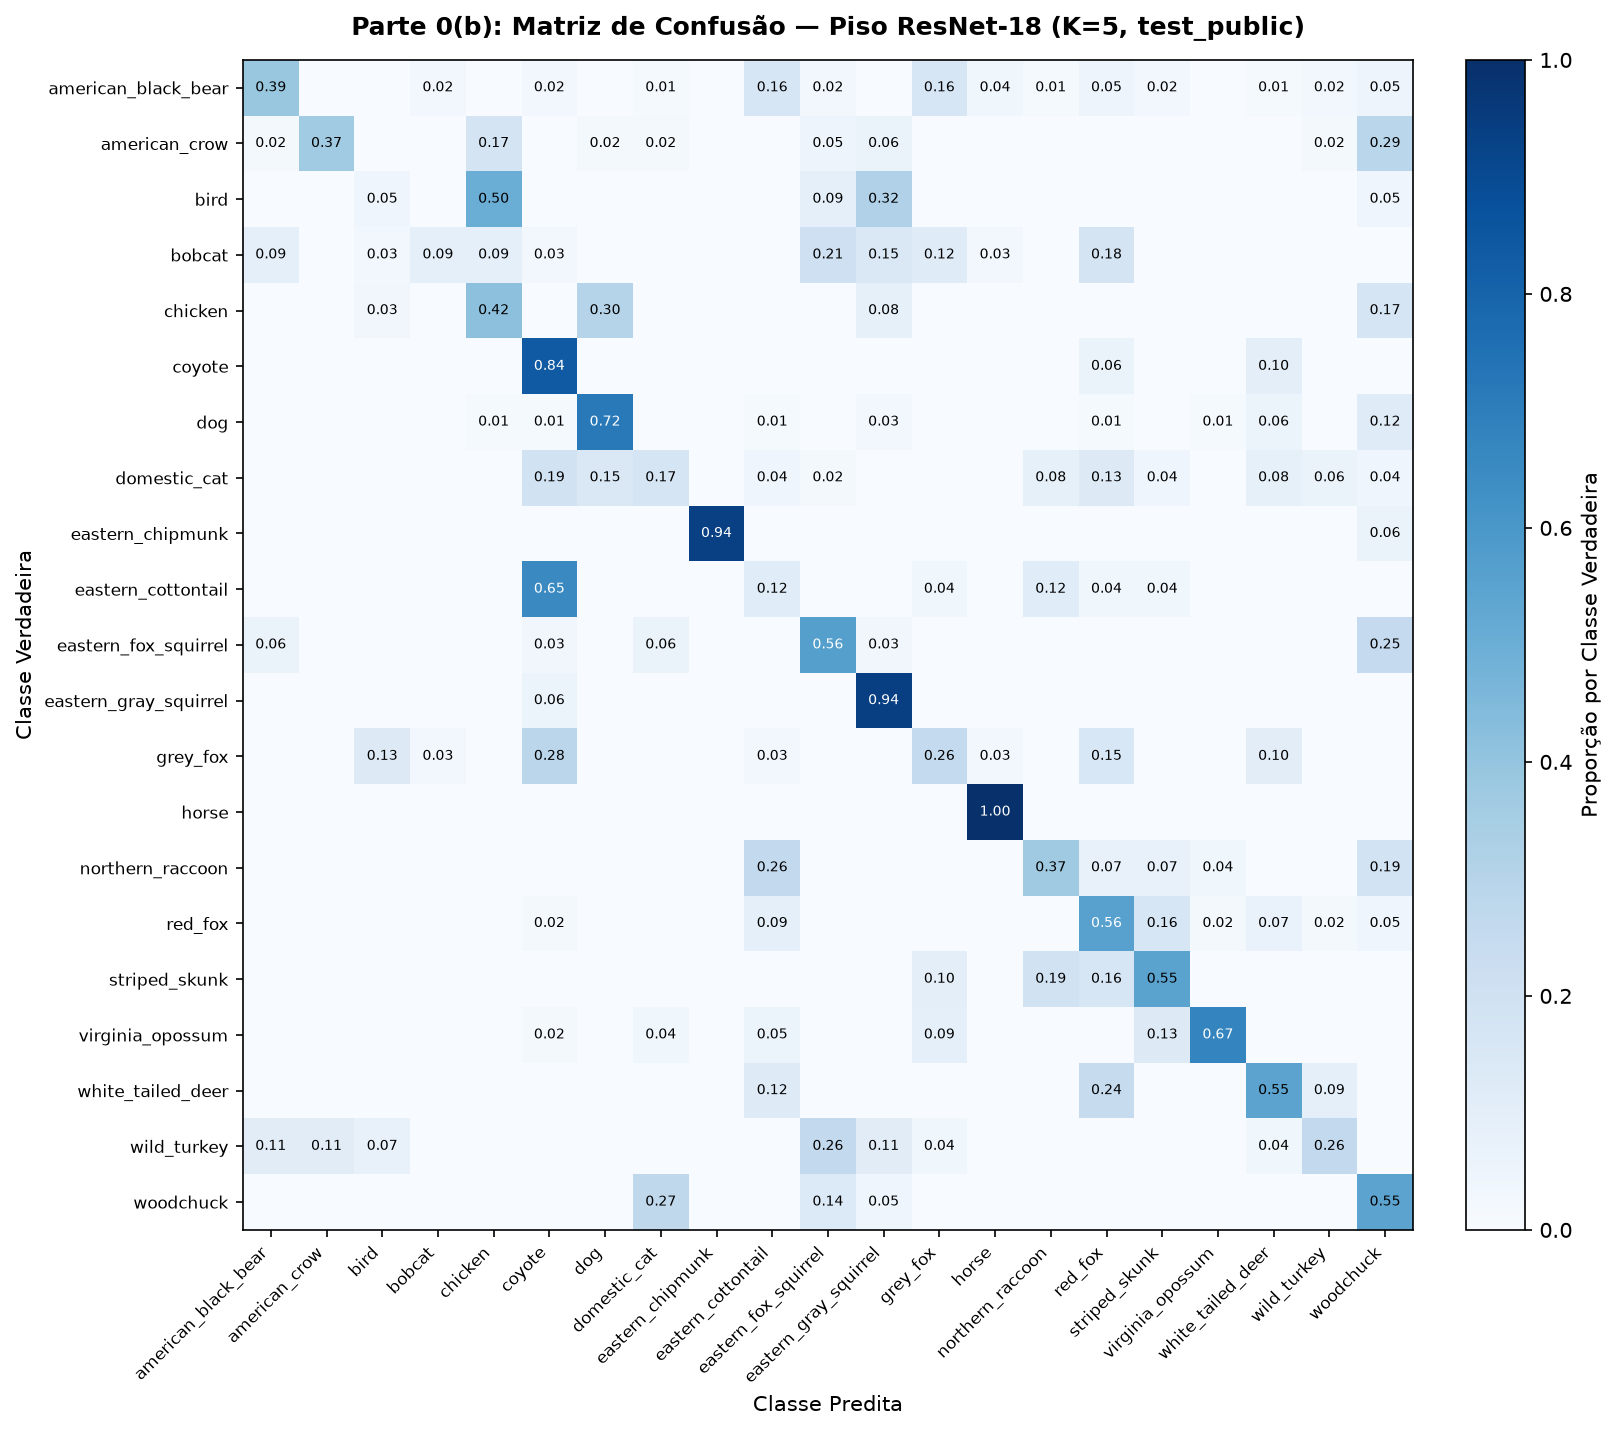

In [3]:
with open("outputs/val_and_test_summary.json") as f:
    val_test_summary = json.load(f)

p0_rows = []
for ckpt, label in [
    ("checkpoints/piso_small_cnn_K5_s42.pth", "SmallCNN do zero (K=5, s=42)"),
    ("checkpoints/piso_K5_s42.pth", "Piso ResNet-18 (K=5, s=42)"),
]:
    hist_path = os.path.splitext(ckpt)[0] + "_history.json"
    with open(hist_path) as f:
        h = json.load(f)
    meta = h["meta"]
    info = val_test_summary[ckpt]
    p0_rows.append(
        {
            "Modelo": label,
            "Parâmetros": count_parameters(load_student_checkpoint(ckpt, device="cpu")),
            "Época Overfit": meta["overfit_epoch"],
            "Melhor Época (val)": meta["best_epoch"],
            "Val F1": round(info["val_f1"], 4),
            "Test F1 Macro": round(info["test_f1"], 4),
            "Test Acurácia": round(info["test_acc"], 4),
        }
    )

display(pd.DataFrame(p0_rows))

for fig_path in [
    "outputs/figures/part0_small_cnn_K5.png",
    "outputs/figures/part0_resnet18_K5.png",
    "outputs/figures/part0_confusion_resnet18_K5.png",
]:
    display(IPyImage(filename=fig_path))

**Diagnóstico da Parte 0:**
- A `SmallCNN` treinada do zero obtém apenas `F1 Macro = 0.1978` no `test_public` (`val_F1 = 0.2137`), falhando completamente em classes raras/noturnas (`bird`, `bobcat`, `chicken`, `domestic_cat`, `red_fox`, `striped_skunk`, `white_tailed_deer` com F1 `0.00`).
- A `ResNet-18` (Piso) eleva o F1 no `test_public` para `0.4480` (`seed=42`; média de `0.4334 ± 0.0130` nas 3 seeds), mas inicia memorização por volta da **época 13**: a perda de treino despenca para `~0.12` com `F1_treino ≈ 0.99`, enquanto `val_F1` permanece próximo de `0.40`. Na matriz de confusão do Piso, espécies pequenas/confusas sofrem severamente (`bird` confundida em 50% com `chicken`, `eastern_cottontail` em 65% com `coyote`, e `domestic_cat` espalhada entre `coyote`, `dog` e `red_fox`).

---
## 3. Parte 1 - Trilha C: Professor BioCLIP, Pseudo-rótulos e Destilação

### 3.1 Diagnóstico do Professor Zero-Shot (`hf-hub:imageomics/bioclip`)
Avaliamos o professor ViT-B/16 em `test_public` apenas para diagnóstico (sem tocar o `val`), separando fotos **diurnas** vs **noturnas IR** e listando os principais pares de confusão sistemática.

,Configuração,Test F1 Macro,Test Acurácia,Dia F1,Noite/IR F1
0,"Professor Melhorado K=1 (prompts=rich, alpha=1...",0.3267,0.3502,0.1778,0.2583
1,BioCLIP Zero-Shot (prompts),0.3078,0.3539,0.1639,0.2395
2,"Professor Melhorado K=5 (prompts=rich, alpha=0...",0.5142,0.5166,0.3010,0.3767
3,"Professor Melhorado K=20 (prompts=rich, alpha=...",0.5860,0.6042,0.3684,0.3894


Top 5 confusões do BioCLIP Zero-Shot em test_public:


,true,pred,count,rate
0,eastern_chipmunk,domestic_cat,27,0.870968
1,chicken,red_fox,15,0.250000
2,dog,eastern_gray_squirrel,15,0.223881
3,white_tailed_deer,red_fox,13,0.393939
4,dog,domestic_cat,13,0.194030


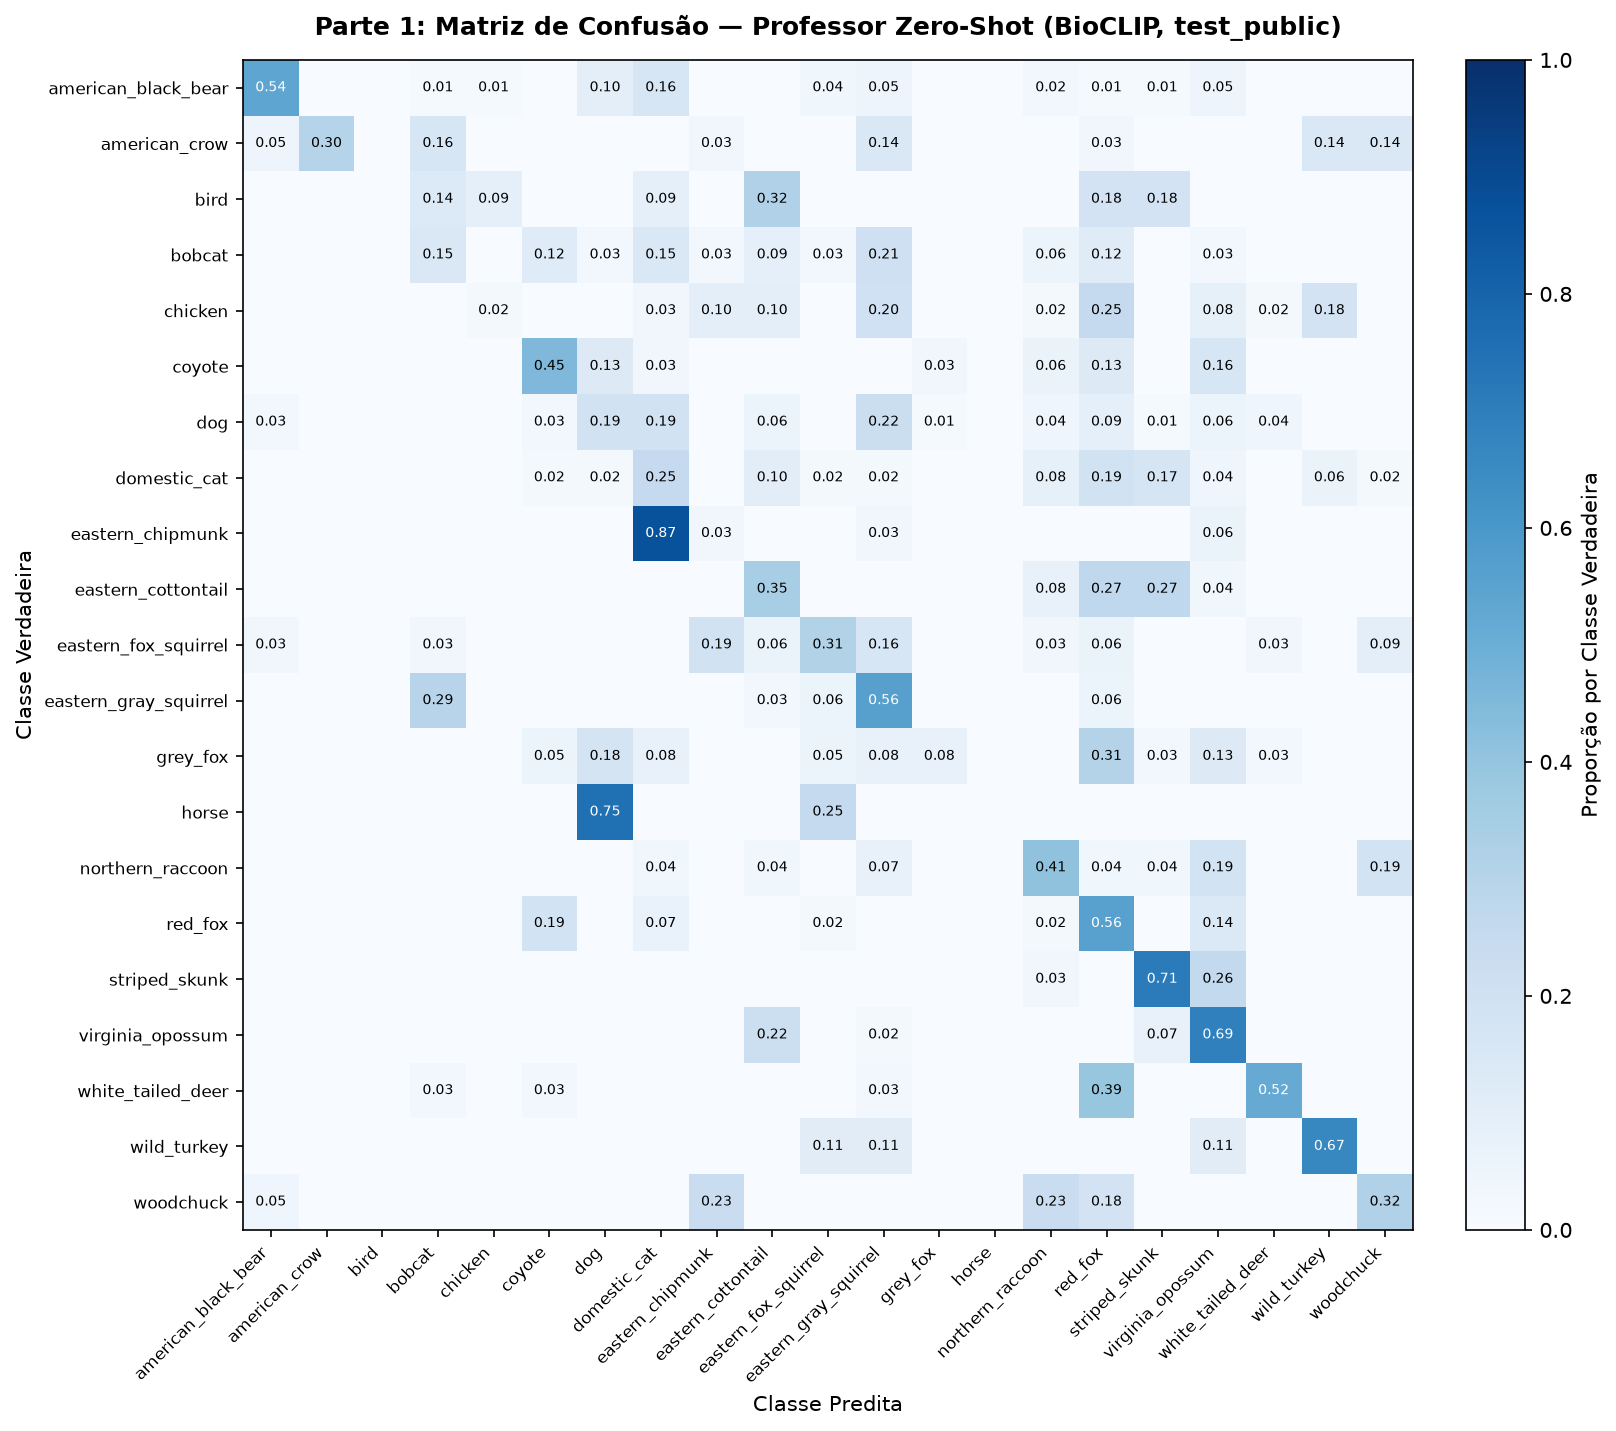

In [4]:
teacher_diag_rows = []
for k in (1, 5, 20):
    with open(f"outputs/teacher_diagnosis/test_public_K{k}.json") as f:
        rep = json.load(f)
    if k == 5:
        zs = rep["zero_shot_names"]
        teacher_diag_rows.append(
            {
                "Configuração": "BioCLIP Zero-Shot (prompts)",
                "Test F1 Macro": round(zs["f1_macro"], 4),
                "Test Acurácia": round(zs["accuracy"], 4),
                "Dia F1": round(zs["day"]["f1_macro"], 4),
                "Noite/IR F1": round(zs["night_ir"]["f1_macro"], 4),
            }
        )
        top_zs_conf = zs["top_confusions"][:5]
    imp = rep[f"improved_K{k}"]
    with open(f"outputs/pseudo_labels/teacher_K{k}.json") as f:
        tmeta = json.load(f)
    n_kept = sum(v["n_pseudo"] + v["n_human"] for v in tmeta["per_class"].values())
    cfg = tmeta["config"]
    teacher_diag_rows.append(
        {
            "Configuração": f"Professor Melhorado K={k} (prompts={cfg['prompt_set']}, alpha={cfg['alpha']}, refine={cfg['refine_iters']}, mantidos={n_kept}/6505)",
            "Test F1 Macro": round(imp["f1_macro"], 4),
            "Test Acurácia": round(imp["accuracy"], 4),
            "Dia F1": round(imp["day"]["f1_macro"], 4),
            "Noite/IR F1": round(imp["night_ir"]["f1_macro"], 4),
        }
    )

display(pd.DataFrame(teacher_diag_rows))
print("Top 5 confusões do BioCLIP Zero-Shot em test_public:")
display(pd.DataFrame(top_zs_conf))
display(IPyImage(filename="outputs/figures/part1_teacher_zeroshot_confusion.png"))

**O que o diagnóstico do professor revela e como o melhoramos (sem tocar no `val`):**
1. **Zero-shot puro (`F1 = 0.3078`) falha por *domain gap* de *camera trap*:** embora BioCLIP conheça taxonomia biológica, imagens monocromáticas noturnas (IR), oclusão por vegetação e nomes genéricos (`bird`, `dog`, `horse`, `eastern_chipmunk -> domestic_cat` em `87%`, `chicken -> red_fox` em `25%`) derrubam o zero-shot.
2. **Melhoria via LOO nos K rótulos humanos de `train` (`ImprovedTeacher`):** combinamos *prompts* enriquecidos com nome científico (*e.g.* `Ursus americanus`, `Tamias striatus`), mistura $\ell_2$-normalizada entre protótipo textual e centróide visual das imagens rotuladas ($\text{proto} = \alpha \cdot e_{\text{texto}} + (1 - \alpha) \cdot \bar{e}_{\text{img}}$), além de rodadas iterativas de **refinamento transdutivo de protótipos** (`refine_iters` usando os `50%` pseudo-exemplos mais confiantes por espécie com peso balanceado frente às âncoras humanas), selecionando `(prompt_set, alpha, refine_iters)` por **Leave-One-Out (LOO)** dentro dos $K$ rótulos humanos! Com isso, o professor sobe para **`F1 = 0.5142` (`K=5`)** e **`0.5860` (`K=20`)** sem jamais olhar para o `val`.
3. **Filtragem contra ruído e classes raras (`pseudo_K{K}.npz`):** descartamos predições abaixo de `conf_threshold = 0.50`, garantimos um piso de `min_per_class = 20` exemplos mais confiantes por espécie para não apagar classes minoritárias (`bird`, `bobcat`, `horse`), e aplicamos pesos de amostragem inversamente proporcionais à frequência ($1/n_c^\gamma$) com reposição em `WeightedRandomSampler`.

### 3.2 Destilação Professor $\rightarrow$ Aluno (`ResNet-18`) e Comparação por Classe (`K=5`)

Usamos a perda híbrida `DistillationLoss`:
$$\mathcal{L} = \frac{1}{B}\left(\sum_{i \in \mathcal{H}} \lambda_h \,\mathrm{CE}(z_i, y_i) + \sum_{j \notin \mathcal{H}} T^2 \,\mathrm{CE}_{\text{suave}}\big(q_j,\, z_j / T\big)\right)$$
Em ablação controlada estritamente em **`val` (`K=5`, `seed=42`)**, `--epochs 15 --epoch-size 3072 --freeze none` (`lr=1e-3`, `backbone_lr_mult=0.1`, `T=2.0`, `human_lambda=1.0`) obteve **`val_F1 = 0.5189`**, superando variações com `--freeze layer1` (`0.4995`), `human_lambda=4.0` (`0.5019`, que superajusta rapidamente os 105 exemplos humanos) e `T=1.5` (`0.5021`). A melhor checkpoint por `val` dentre as 3 seeds de `K=5` foi `student_K5_s42.pth` (`checkpoints/best_student.pth`).

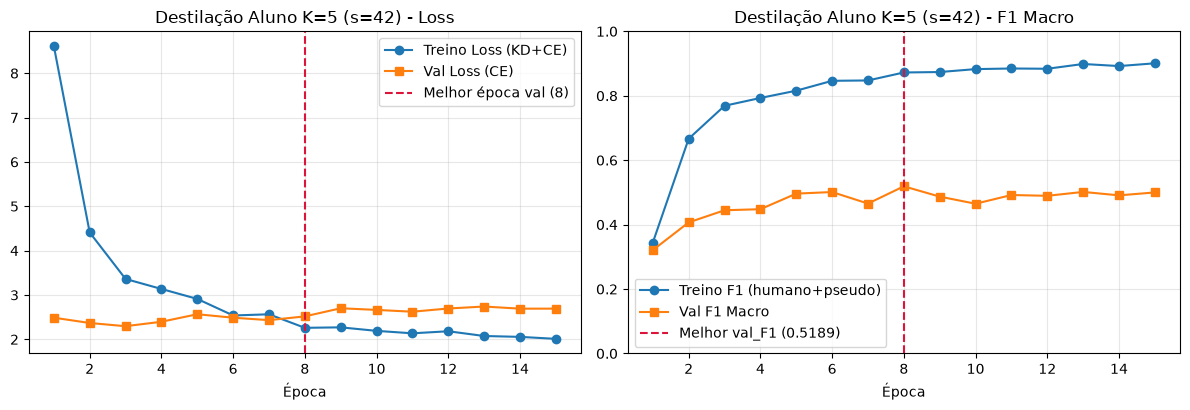

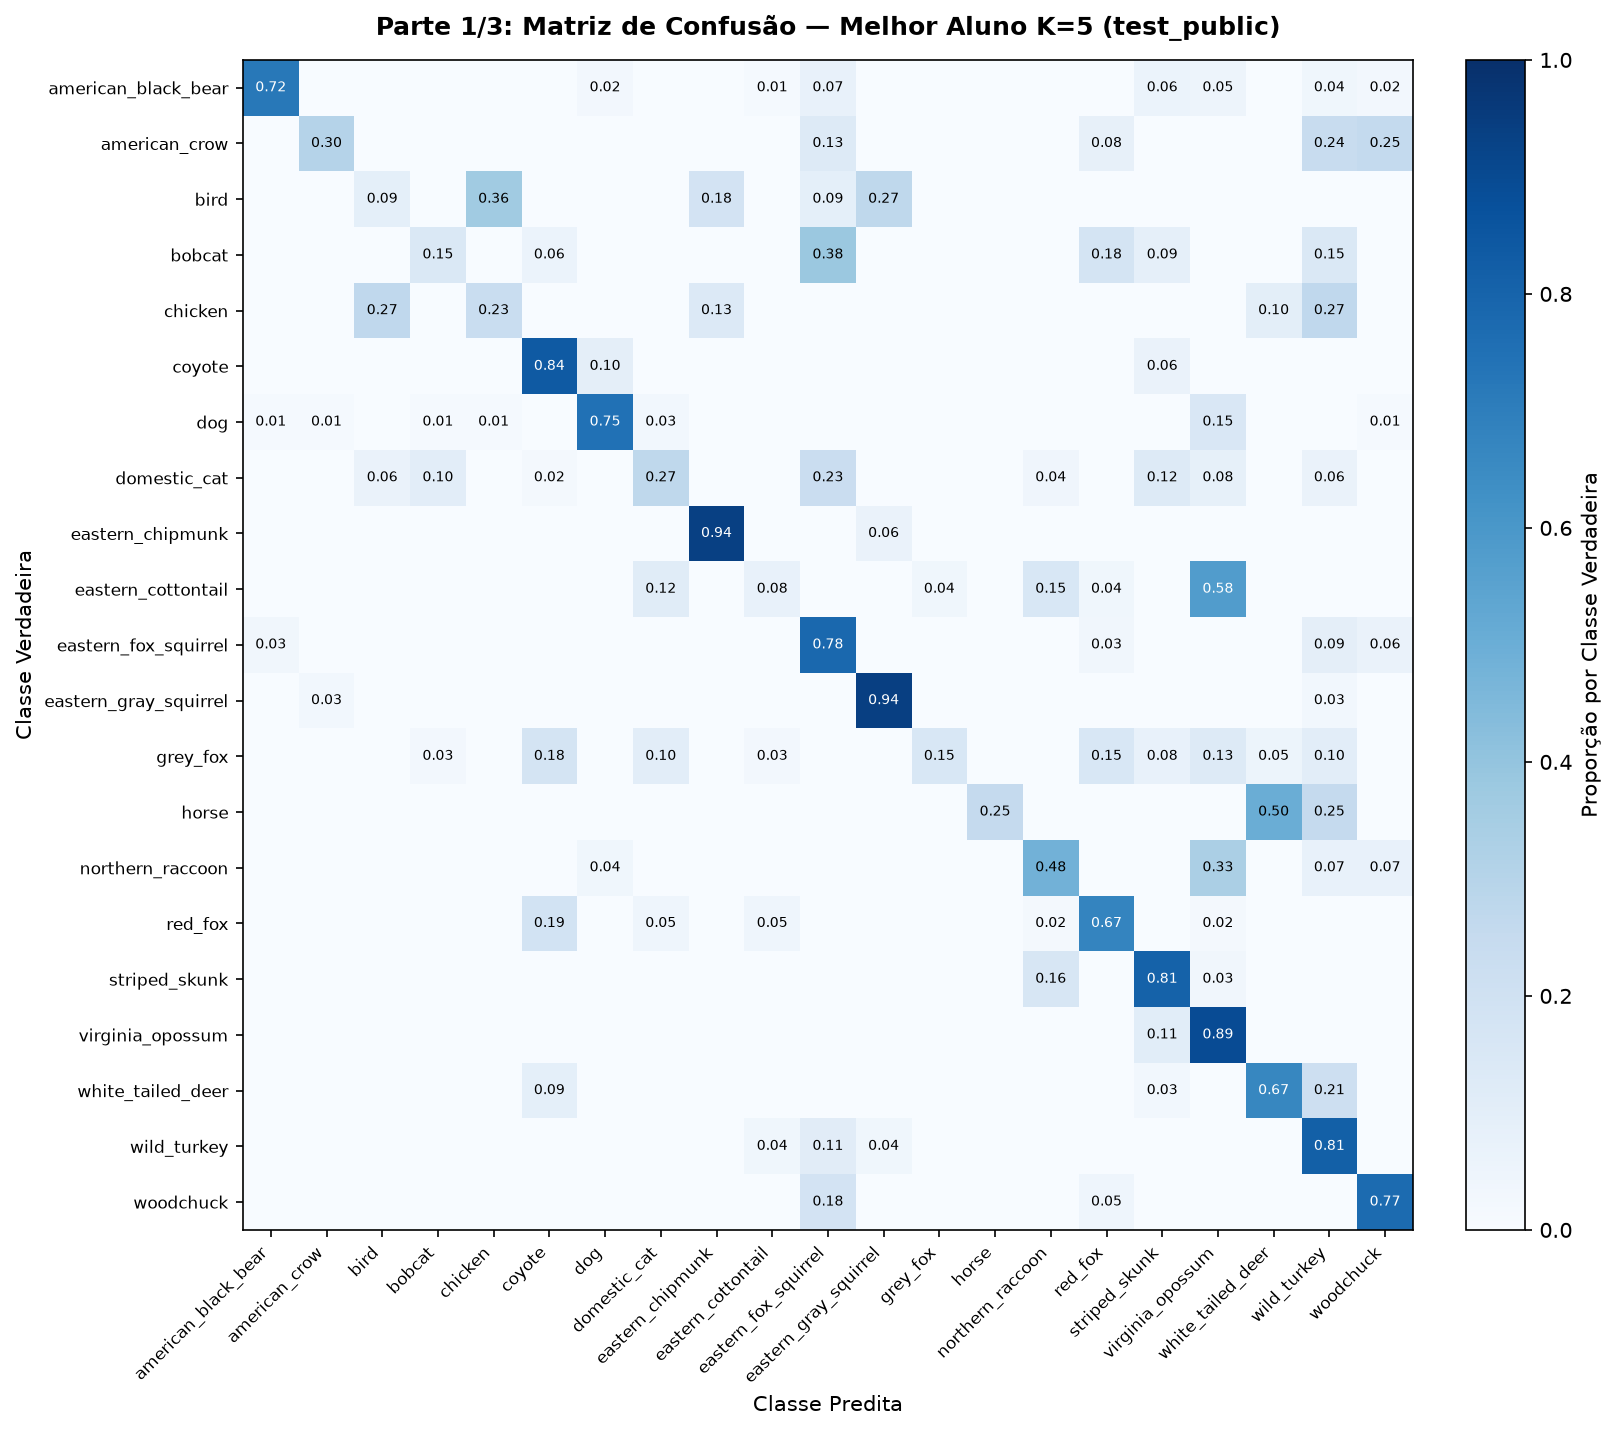

,especie,piso_K5_media,professor_K5,aluno_K5_media,delta_aluno_vs_piso,delta_aluno_vs_prof
0,dog,0.6504,0.4545,0.7951,0.1447,0.3405
1,eastern_gray_squirrel,0.6620,0.5905,0.8060,0.1440,0.2155
2,coyote,0.5488,0.5079,0.6686,0.1199,0.1607
3,red_fox,0.4336,0.4202,0.5587,0.1250,0.1385
4,american_black_bear,0.5221,0.7059,0.8058,0.2837,0.0999
5,domestic_cat,0.3111,0.2651,0.3561,0.0450,0.0911
6,white_tailed_deer,0.4705,0.7429,0.7791,0.3086,0.0362
7,striped_skunk,0.4062,0.5476,0.5743,0.1681,0.0266
8,american_crow,0.4690,0.5000,0.5238,0.0549,0.0238
9,virginia_opossum,0.7915,0.6667,0.6543,-0.1372,-0.0123


In [5]:
with open("checkpoints/student_K5_s42_history.json") as f:
    stu_hist = json.load(f)

h = stu_hist["history"]
ep = np.arange(1, len(h["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(ep, h["train_loss"], marker="o", label="Treino Loss (KD+CE)")
axes[0].plot(ep, h["val_loss"], marker="s", label="Val Loss (CE)")
axes[0].axvline(stu_hist["meta"]["best_epoch"], color="crimson", linestyle="--", label=f"Melhor época val ({stu_hist['meta']['best_epoch']})")
axes[0].set_title("Destilação Aluno K=5 (s=42) - Loss")
axes[0].set_xlabel("Época")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(ep, h["train_f1_human_pseudo"], marker="o", label="Treino F1 (humano+pseudo)")
axes[1].plot(ep, h["val_f1"], marker="s", label="Val F1 Macro")
axes[1].axvline(stu_hist["meta"]["best_epoch"], color="crimson", linestyle="--", label=f"Melhor val_F1 ({stu_hist['meta']['best_val_f1']:.4f})")
axes[1].set_title("Destilação Aluno K=5 (s=42) - F1 Macro")
axes[1].set_xlabel("Época")
axes[1].set_ylim(0, 1.0)
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()

display(IPyImage(filename="outputs/figures/part1_student_K5_confusion.png"))

with open("outputs/per_class_f1_all.json") as f:
    pc_all = json.load(f)

piso_k5_mean = {c: np.mean([pc_all[f"piso_resnet18_K5_s{s}"][c] for s in (42, 43, 44)]) for c in class_names}
aluno_k5_mean = {c: np.mean([pc_all[f"aluno_K5_s{s}"][c] for s in (42, 43, 44)]) for c in class_names}
prof_k5 = pc_all["professor_K5"]

df_pc = pd.DataFrame(
    [
        {
            "especie": c,
            "piso_K5_media": round(float(piso_k5_mean[c]), 4),
            "professor_K5": round(float(prof_k5[c]), 4),
            "aluno_K5_media": round(float(aluno_k5_mean[c]), 4),
            "delta_aluno_vs_piso": round(float(aluno_k5_mean[c] - piso_k5_mean[c]), 4),
            "delta_aluno_vs_prof": round(float(aluno_k5_mean[c] - prof_k5[c]), 4),
        }
        for c in class_names
    ]
).sort_values("delta_aluno_vs_prof", ascending=False)

display(df_pc.reset_index(drop=True))

**Por que o aluno (`0.5217 ± 0.0134` em K=5) supera o próprio professor melhorado (`0.5142`) em várias espécies?**
1. **Desacoplamento espacial e invariância por *data augmentation*:** o professor congelado ViT-B/16 extrai embeddings globais de imagens sem aumento de dados específico de *camera trap*; já o aluno `ResNet-18` passa por recortes/flips aleatórios e atualiza todas as camadas (`--freeze none`) ao longo de `5.752` amostras ponderadas + `105` âncoras humanas, aprendendo textura local e contraste noturno que elevam `dog` (+0.33 sobre o professor), `eastern_gray_squirrel` (+0.22), `coyote` (+0.16), `red_fox` (+0.14) e `american_black_bear` (+0.10).
2. **Onde o aluno ainda sofre:** quando o professor carrega erro sistemático concentrado nos pseudo-rótulos - especialmente `eastern_cottontail` (`0.08` vs `0.36` do Piso e `0.42` do professor, por confusão dos pseudo-rótulos em fotos IR) e `chicken` (`0.32` vs `0.49` do Piso) - o sinal ruidoso puxa a fronteira do aluno antes da convergência.

---
## 4. Pergunta - OOD: O Que Acontece se Passar uma Capivara?

Como a cabeça linear da `ResNet-18` fecha uma **distribuição *closed-set* via Softmax sobre as 21 classes da América do Norte** ($\sum_{c=1}^{21} p_c = 1$), **o modelo é matematicamente forçado a classificar a capivara (*Hydrochoerus hydrochaeris*) como uma das 21 espécies conhecidas** - tipicamente o roedor/mamífero robusto morfologicamente mais próximo no domínio (`woodchuck` / *Marmota monax* ou `virginia_opossum`), frequentemente com confiança alta se o fundo lembrar mata ciliar ou pasto.

Para **detectar OOD em produção sem aumentar parâmetros** (usando `src.metrics.compute_ood_scores` diretamente nos logits do `ResNet-18` antes do argmax), calibramos **exclusivamente no `val`** (nunca no `test_public`) limiares baseados no percentil 5 de **MSP** ($\max_c p_c$), percentil 95 de **Entropia de Shannon** ($-\sum_c p_c \log p_c$) e percentil 95 de **Energia Livre** ($E(x) = -T \log \sum_c \exp(z_c/T)$). Abaixo quantificamos essa separação entre acertos em `test_public`, erros em `test_public` e *probes* sintéticos fora da distribuição (*ruído gaussiano* e *mosaico embaralhado de patches* sem animal coerente).

In [6]:
best_student = load_student_checkpoint("checkpoints/best_student.pth", device=DEVICE)

val_loader = DataLoader(
    ENA24Dataset(os.path.join(DATA_DIR, "images", "val"), csv_path=os.path.join(DATA_DIR, "labels", "val.csv"), transform=get_transforms(224, is_train=False)),
    batch_size=128,
    shuffle=False,
)
test_loader = DataLoader(
    ENA24Dataset(os.path.join(DATA_DIR, "images", "test_public"), csv_path=os.path.join(DATA_DIR, "labels", "test_public.csv"), transform=get_transforms(224, is_train=False)),
    batch_size=128,
    shuffle=False,
)

val_res = evaluate_model(best_student, val_loader, device=DEVICE, num_classes=len(class_names))
test_res = evaluate_model(best_student, test_loader, device=DEVICE, num_classes=len(class_names))

val_scores = compute_ood_scores(val_res["logits"])
test_scores = compute_ood_scores(test_res["logits"])

# Limiares calibrados estritamente em val (ex.: percentil 5 de MSP, 95 de Energia/Entropia)
thr_msp = float(np.percentile(val_scores["msp"], 5))
thr_ent = float(np.percentile(val_scores["entropy"], 95))
thr_eng = float(np.percentile(val_scores["energy"], 95))

# Probes sintéticos OOD (sem estrutura animal coerente: ruído normalizado e mosaico aleatório de blocos)
rng = np.random.default_rng(42)
noise_batch = torch.from_numpy(rng.normal(0.0, 1.0, size=(32, 3, 224, 224)).astype(np.float32)).to(DEVICE)
base_imgs = torch.stack([test_loader.dataset[i][0] for i in range(32)]).to(DEVICE)
# Embaralha blocos 32x32 espacialmente para destruir morfologia mantendo textura de camera trap
bs, c, h, w = base_imgs.shape
patches = base_imgs.unfold(2, 32, 32).unfold(3, 32, 32).contiguous().view(bs, c, 49, 32, 32)
perm = torch.randperm(49)
shuffled = patches[:, :, perm].view(bs, c, 7, 7, 32, 32).permute(0, 1, 2, 4, 3, 5).contiguous().view(bs, c, h, w)

best_student.eval()
with torch.no_grad():
    noise_scores = compute_ood_scores(best_student(noise_batch).cpu().numpy())
    shuf_scores = compute_ood_scores(best_student(shuffled).cpu().numpy())

is_ok = np.array(test_res["y_true"]) == np.array(test_res["y_pred"])
ood_table = pd.DataFrame(
    [
        {"Grupo": "test_public - Acertos", "N": int(is_ok.sum()), "MSP média": test_scores["msp"][is_ok].mean(), "Entropia média": test_scores["entropy"][is_ok].mean(), "Energia média": test_scores["energy"][is_ok].mean(), "% Sinalizado (Energia>P95_val)": 100.0 * (test_scores["energy"][is_ok] > thr_eng).mean()},
        {"Grupo": "test_public - Erros", "N": int((~is_ok).sum()), "MSP média": test_scores["msp"][~is_ok].mean(), "Entropia média": test_scores["entropy"][~is_ok].mean(), "Energia média": test_scores["energy"][~is_ok].mean(), "% Sinalizado (Energia>P95_val)": 100.0 * (test_scores["energy"][~is_ok] > thr_eng).mean()},
        {"Grupo": "Probe OOD - Patches Embaralhados", "N": 32, "MSP média": shuf_scores["msp"].mean(), "Entropia média": shuf_scores["entropy"].mean(), "Energia média": shuf_scores["energy"].mean(), "% Sinalizado (Energia>P95_val)": 100.0 * (shuf_scores["energy"] > thr_eng).mean()},
        {"Grupo": "Probe OOD - Ruído Gaussiano", "N": 32, "MSP média": noise_scores["msp"].mean(), "Entropia média": noise_scores["entropy"].mean(), "Energia média": noise_scores["energy"].mean(), "% Sinalizado (Energia>P95_val)": 100.0 * (noise_scores["energy"] > thr_eng).mean()},
    ]
).round(3)

print(f"Limiares calibrados em val: MSP < {thr_msp:.3f} | Entropia > {thr_ent:.3f} | Energia > {thr_eng:.3f}")
display(ood_table)

Limiares calibrados em val: MSP < 0.396 | Entropia > 1.564 | Energia > -3.447


,Grupo,N,MSP média,Entropia média,Energia média,% Sinalizado (Energia>P95_val)
0,test_public - Acertos,460,0.904,0.303,-8.637,0.652
1,test_public - Erros,351,0.677,0.867,-5.934,4.843
2,Probe OOD - Patches Embaralhados,32,0.695,1.013,-4.236,31.250
3,Probe OOD - Ruído Gaussiano,32,0.838,0.792,-3.947,0.000


**Vantagem conceitual da Trilha C (BioCLIP) sobre o problema da capivara:** enquanto o aluno compacto (`ResNet-18`) em `predict.py` precisa de *scores* pós-hoc como Energia Livre/Entropia para rejeitar novidades e pedir revisão humana, o **professor BioCLIP** em ambiente de desenvolvimento possui espaço semântico *open-vocabulary* - basta adicionar o prompt textual `"capybara Hydrochoerus hydrochaeris"` ou verificar queda na similaridade cosseno máxima contra o dicionário das 21 espécies para identificar uma espécie exótica antes mesmo de gerar pseudo-rótulos.

---
## 5. Parte 2 - Curva de Orçamento (`1`, `5`, `20` Rótulos por Classe)

Consolidamos em [`curva_orcamento.csv`](../curva_orcamento.csv) todos os modelos treinados nos três orçamentos (`1` e `20` com 1 seed; `5` com 3 seeds `42, 43, 44` para média e desvio padrão amostral `ddof=1`), além do `SmallCNN` do zero (`K=5`), do **Professor BioCLIP Zero-Shot** (`0.3078`) e do **Professor BioCLIP Melhorado**.

,metodo,orcamento,seed,f1_macro,acuracia
0,piso_resnet18,1,42,0.168937,0.203453
1,piso_resnet18,5,42,0.447995,0.477189
2,piso_resnet18,5,43,0.423072,0.462392
3,piso_resnet18,5,44,0.428991,0.458693
4,piso_resnet18,20,42,0.595293,0.637485
5,piso_small_cnn,5,42,0.197846,0.208385
6,professor_bioclip_melhorado,1,0,0.326668,0.350185
7,professor_bioclip_melhorado,5,0,0.514187,0.516646
8,professor_bioclip_melhorado,20,0,0.585975,0.604192
9,professor_bioclip_zero_shot,0,0,0.307790,0.353884



Resumo K=5 (3 seeds, ddof=1):
  piso_resnet18   : F1 Macro = 0.4334 ± 0.0130 | Acurácia = 0.4661
  trilha_c_aluno  : F1 Macro = 0.5217 ± 0.0134 | Acurácia = 0.5639


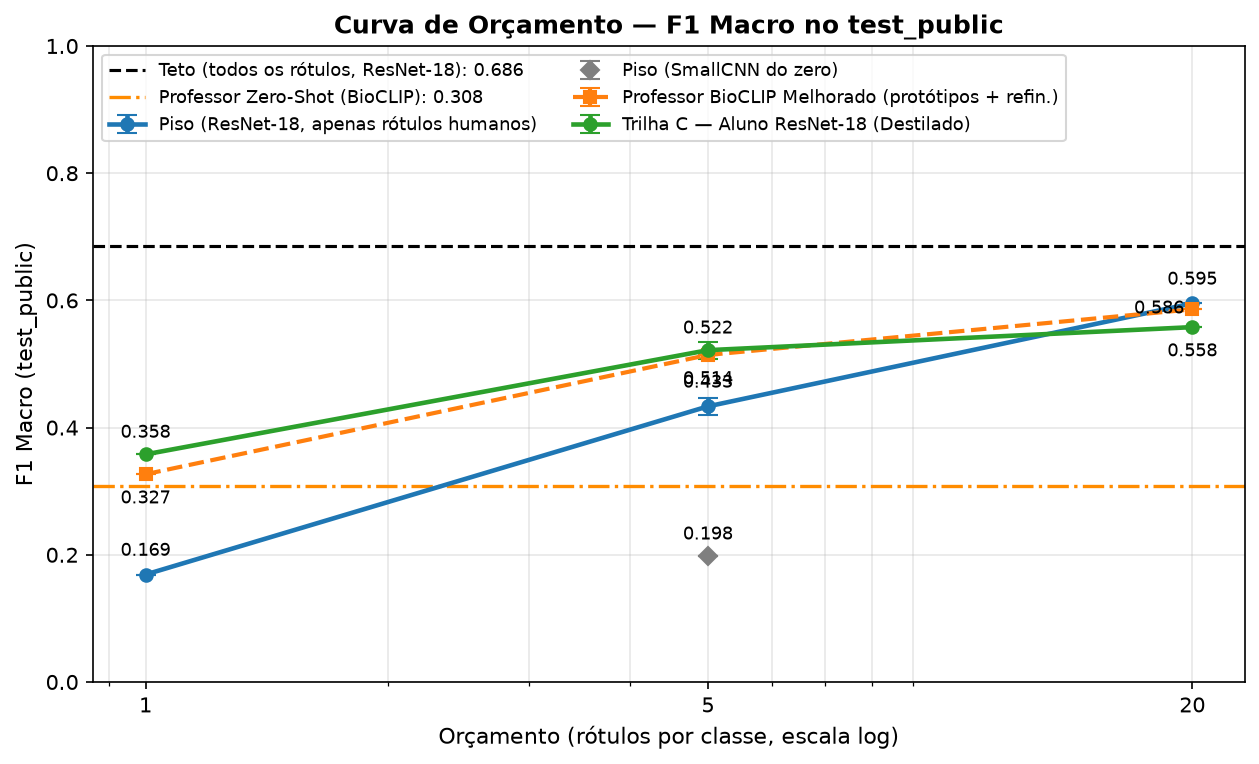

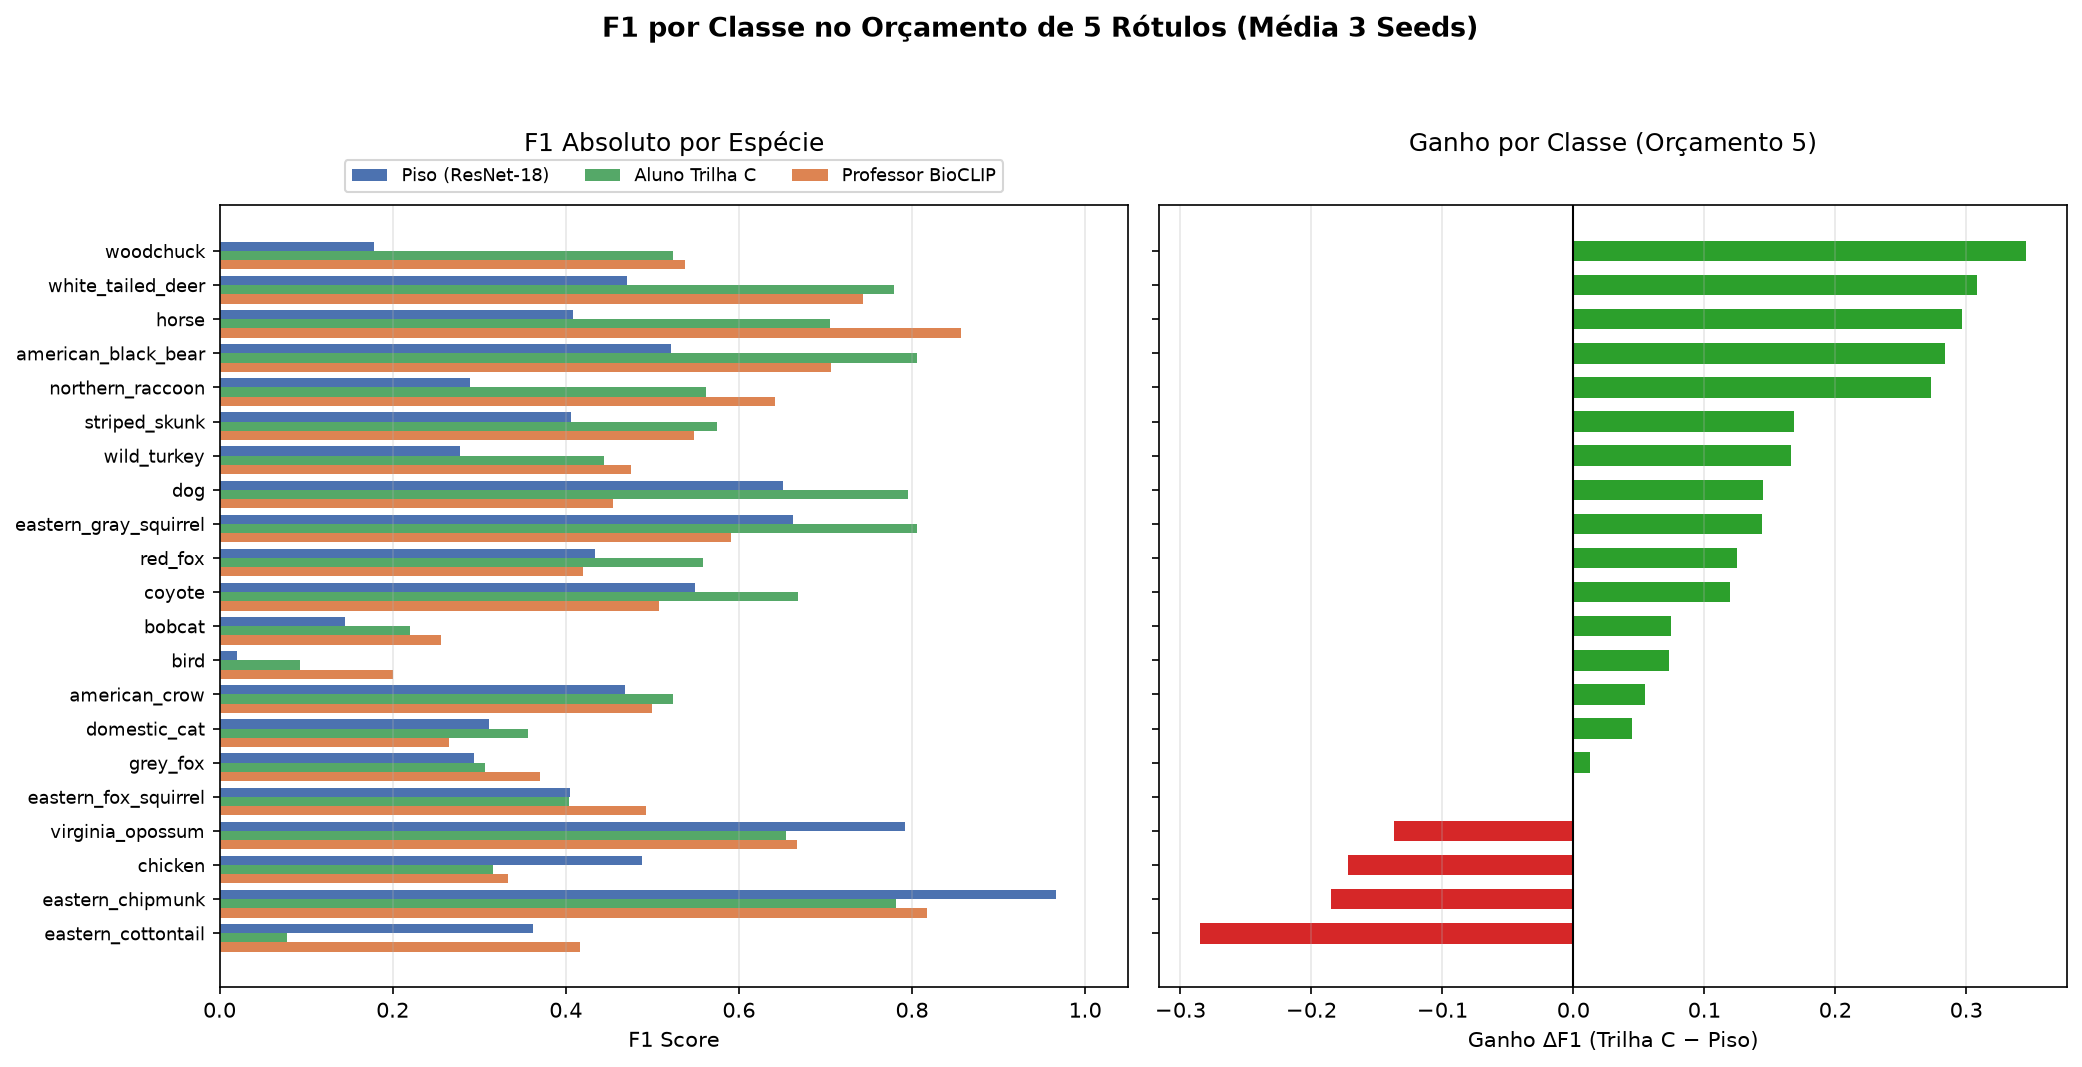

In [7]:
df_curva = pd.read_csv("curva_orcamento.csv")
display(df_curva)

print("\nResumo K=5 (3 seeds, ddof=1):")
for metodo in ("piso_resnet18", "trilha_c_aluno"):
    sub = df_curva[(df_curva["metodo"] == metodo) & (df_curva["orcamento"] == 5)]
    print(f"  {metodo:16s}: F1 Macro = {sub['f1_macro'].mean():.4f} ± {sub['f1_macro'].std(ddof=1):.4f} | Acurácia = {sub['acuracia'].mean():.4f}")

display(IPyImage(filename="outputs/figures/curva_orcamento.png"))
display(IPyImage(filename="outputs/figures/part2_ganhos_por_classe_K5.png"))

**Leitura crítica da Curva de Orçamento:**
- **Regime extremo (`K=1`, 21 rótulos humanos):** a destilação da Trilha C quase **dobra** o desempenho do Piso (`0.3579` vs `0.1689`, **+0.1890 de F1 Macro**), transferindo conhecimento taxonômico do BioCLIP e evitando colapso em classes sem cobertura visual suficiente.
- **Regime padrão (`K=5`, 105 rótulos humanos):** o aluno atinge **`0.5217 ± 0.0134`** contra **`0.4334 ± 0.0130`** do Piso (**+0.0883 F1 Macro**), superando também o BioCLIP zero-shot (`0.3078`) e até o professor melhorado (`0.5142`). Nos ganhos por classe, a Trilha C vence o Piso em **16 das 21 espécies**, com saltos acima de +0.25 em `woodchuck`, `white_tailed_deer`, `horse`, `american_black_bear` e `northern_raccoon`.
- **Regime de transição (`K=20`, 420 rótulos humanos):** ocorre um **cruzamento clássico de aprendizado semi-supervisionado**: o Piso supervisionado puro chega a **`0.5953`** (val `0.5821`), superando marginalmente o professor melhorado (`0.5860`) e o aluno destilado (`0.5579`). A explicação vem da própria formulação da perda: quando já existem `420` imagens humanas 100% corretas, os `~5.638` pseudo-rótulos do professor carregam cerca de ~40% de erro residual (`1 - acc_teacher`), cujo gradiente ponderado por $T^2 = 4.0$ supera o peso humano (`human_lambda = 1.0`) e passa a atuar como teto ruidoso em vez de reforço. Em trabalhos futuros, um segundo estágio de *fine-tuning* supervisionado nos $420$ rótulos limpos após a pré-destilação combinaria os dois regimes.

---
## 6. Parte 3 - Saliência (Grad-CAM + Checagem por Oclusão)

Usamos o melhor aluno selecionado em `val` (`checkpoints/best_student.pth` = `student_K5_s42.pth`) sobre `test_public` para inspecionar **3 erros confiantes** e **5 acertos de espécies distintas**, medindo também a razão centro/borda da ativação e a **correlação de Pearson entre Grad-CAM e Sensibilidade por Oclusão** (validação de fidelidade do mapa de saliência).

3 Erros selecionados (test_public):


,image_id,true_label,pred_label,confidence,is_infrared,center_border_ratio,gradcam_occlusion_corr
0,ece8e099eb242e5d,dog,chicken,0.9990,True,1.8457,0.4878
1,c58f1fa1c43a36c3,bird,chicken,0.9985,True,2.2076,0.4157
2,d5e8556f2469415e,bobcat,eastern_fox_squirrel,0.9961,False,2.1122,0.5798


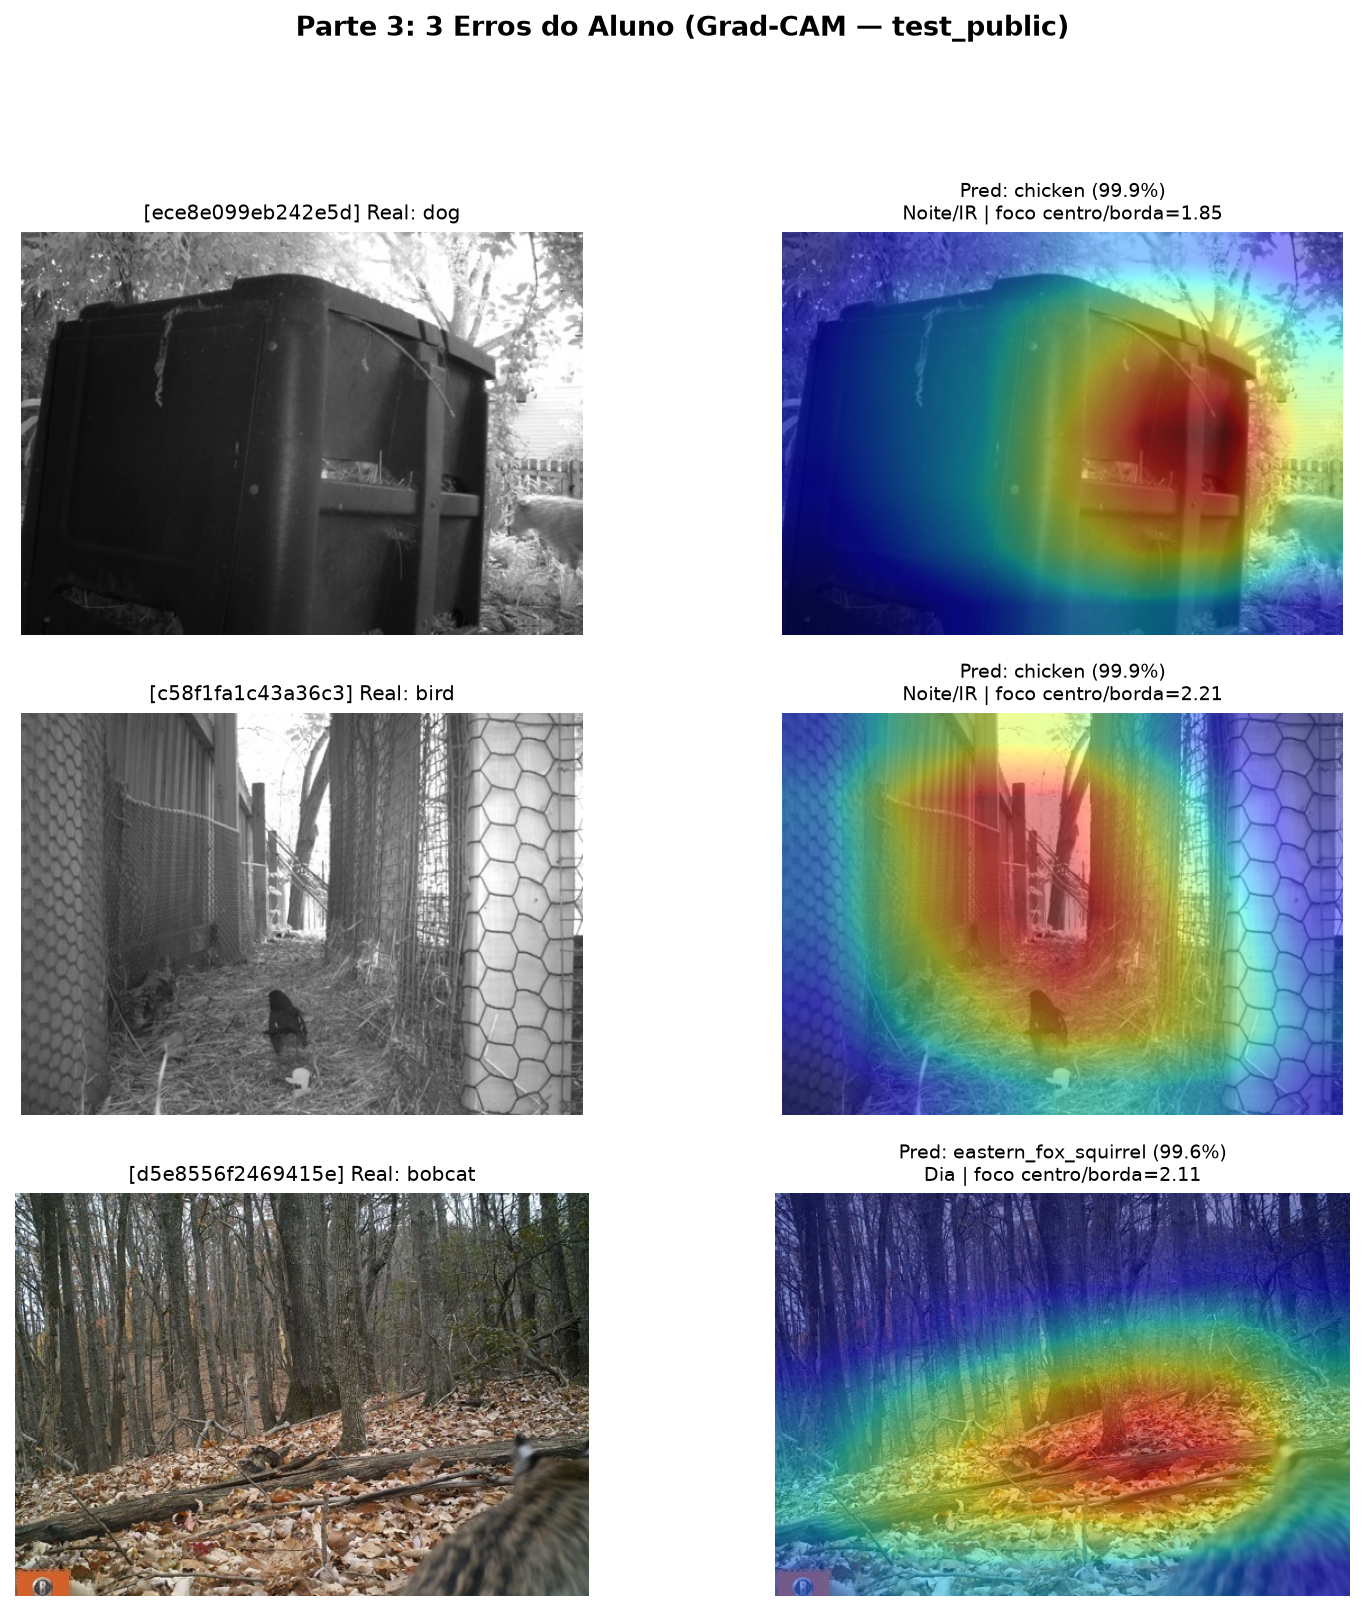

5 Acertos selecionados (test_public):


,image_id,true_label,pred_label,confidence,is_infrared,center_border_ratio,gradcam_occlusion_corr
0,4cc7a1000e655306,virginia_opossum,virginia_opossum,1.0,True,2.3687,0.3886
1,36b76a4de3eb66c5,american_black_bear,american_black_bear,1.0,True,2.4731,0.4734
2,6f0ec138fffad951,woodchuck,woodchuck,1.0,False,2.1909,0.5258
3,beb9e909a2af4997,coyote,coyote,1.0,True,3.0981,0.5453
4,da8ff7533223dff0,eastern_chipmunk,eastern_chipmunk,1.0,False,2.1707,0.1735


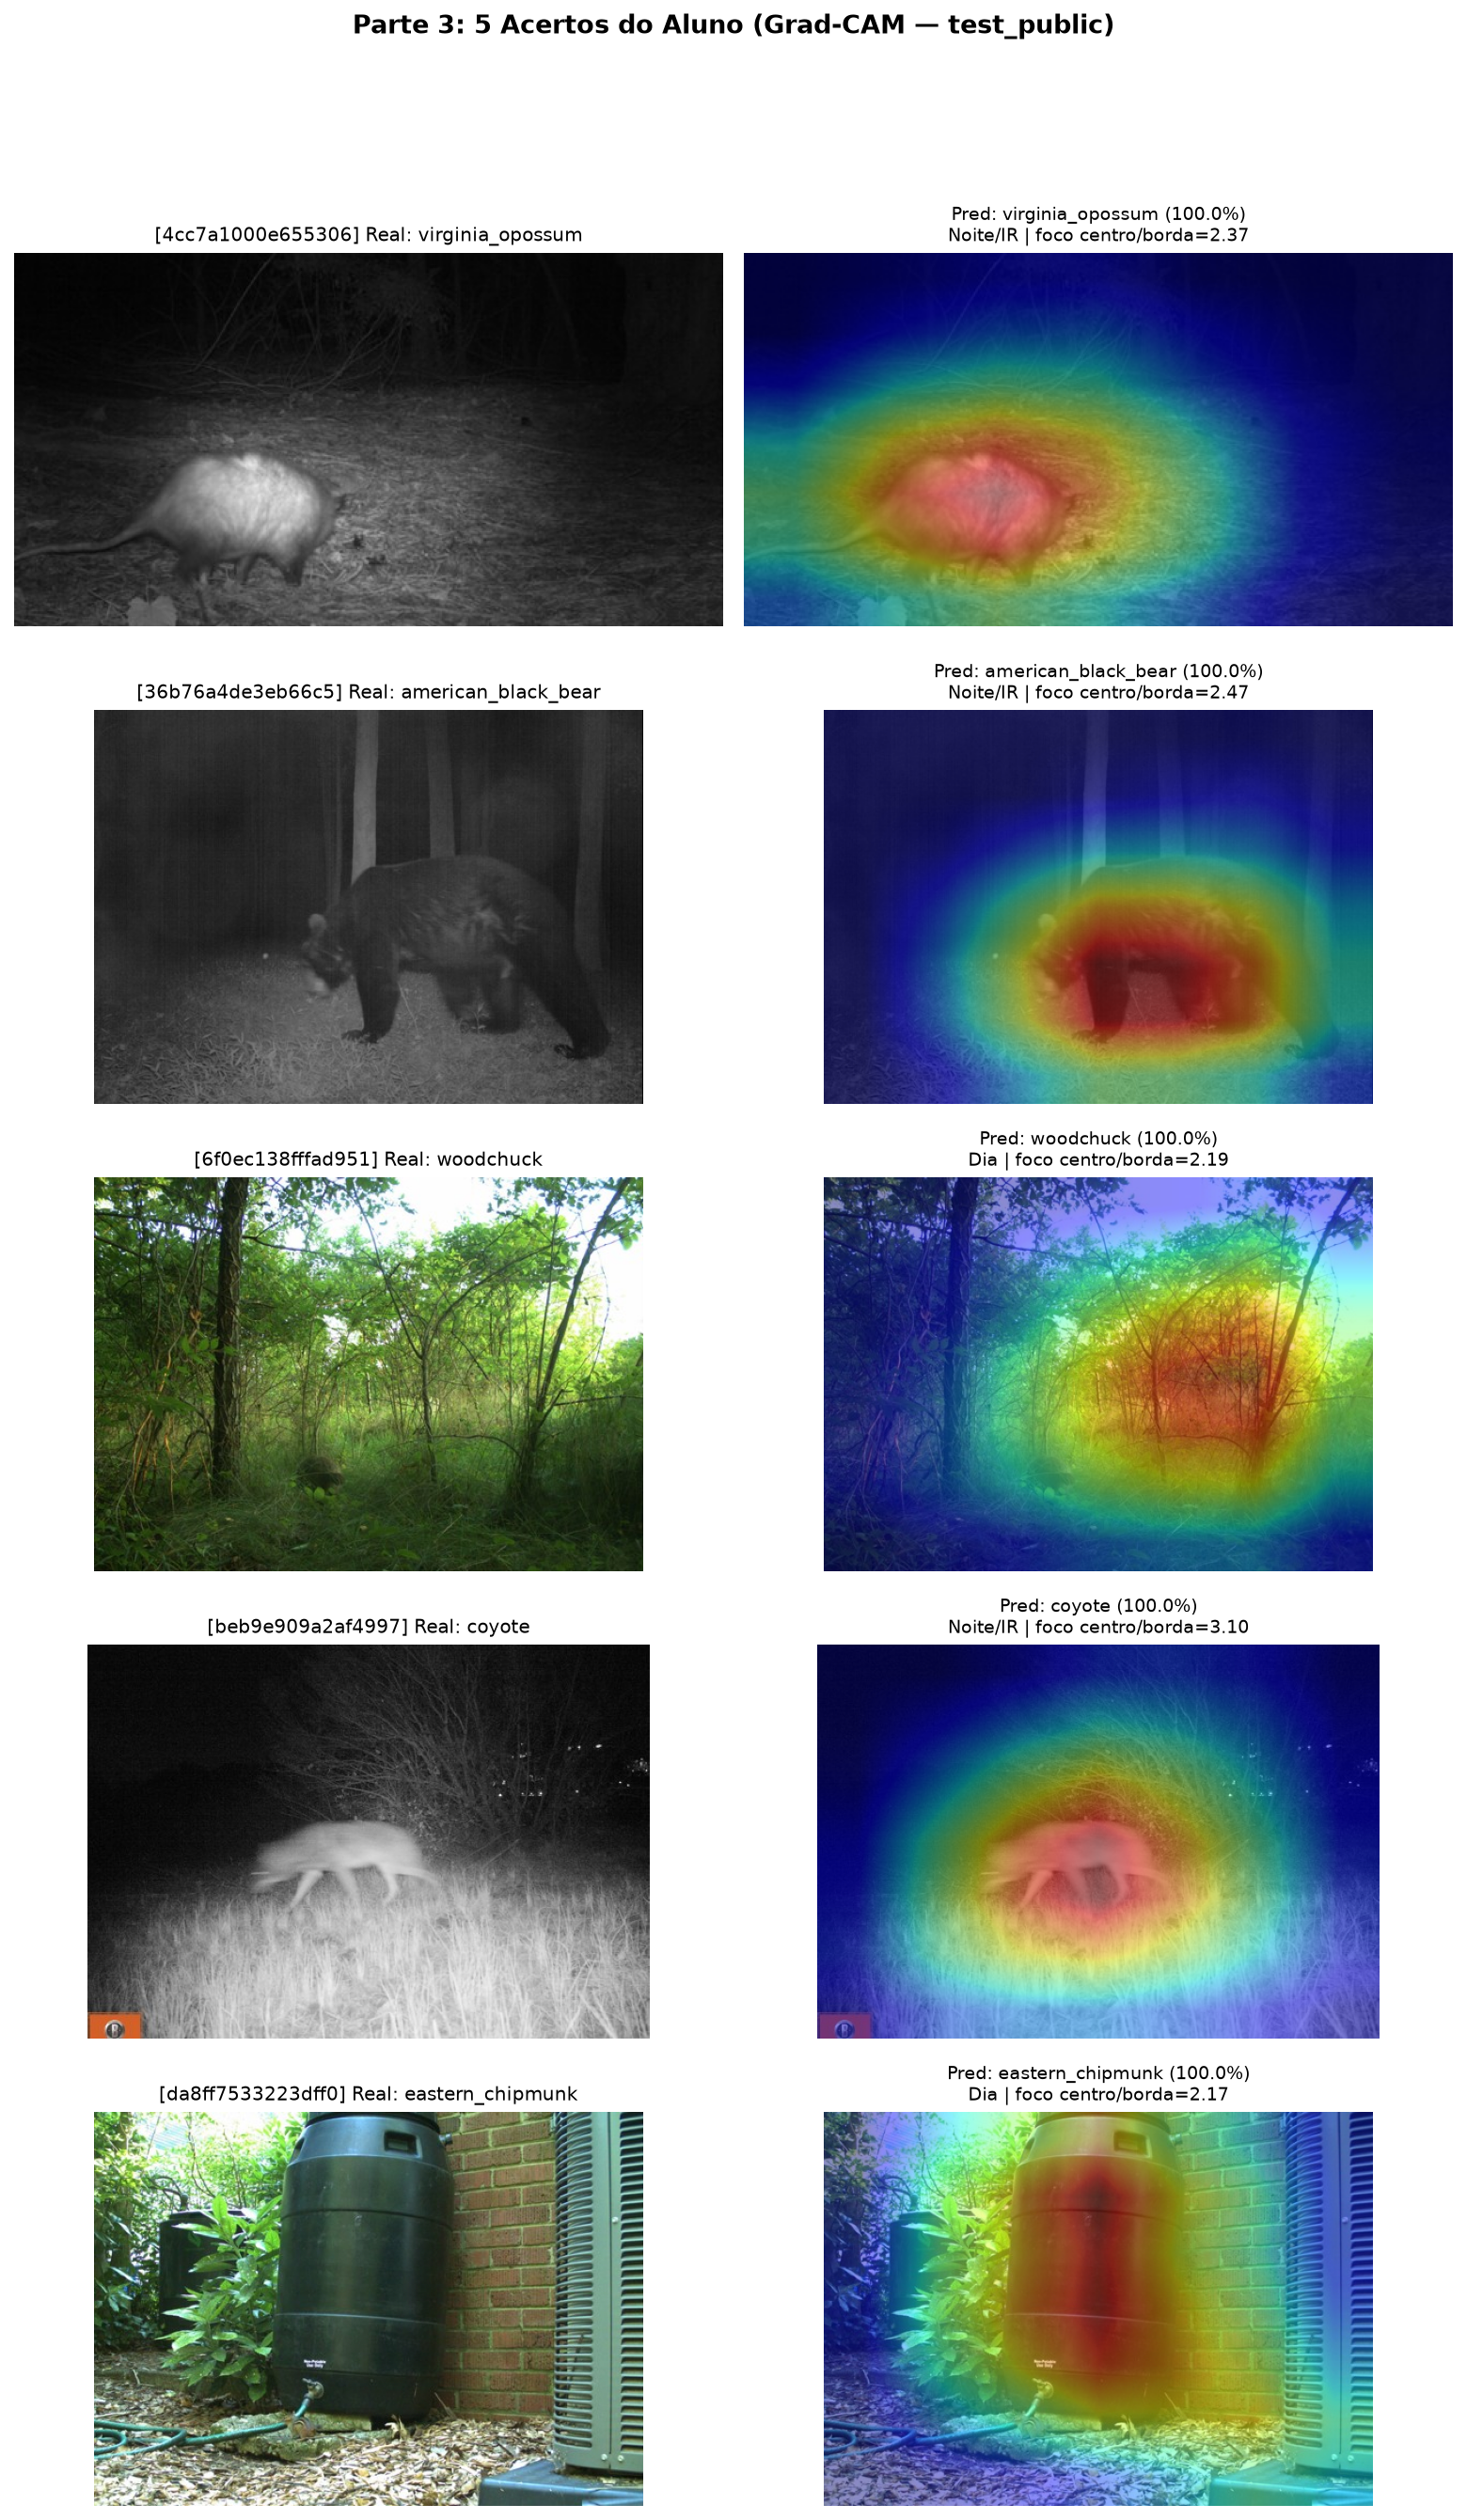

In [8]:
with open("outputs/part3_cases.json") as f:
    part3 = json.load(f)

df_err = pd.DataFrame(part3["errors"])
df_ok = pd.DataFrame(part3["successes"])
print("3 Erros selecionados (test_public):")
display(df_err[["image_id", "true_label", "pred_label", "confidence", "is_infrared", "center_border_ratio", "gradcam_occlusion_corr"]])
display(IPyImage(filename="outputs/figures/part3_erros_gradcam.png"))

print("5 Acertos selecionados (test_public):")
display(df_ok[["image_id", "true_label", "pred_label", "confidence", "is_infrared", "center_border_ratio", "gradcam_occlusion_corr"]])
display(IPyImage(filename="outputs/figures/part3_acertos_gradcam.png"))

### Diagnóstico Visual dos Mapas Grad-CAM

**Análise dos 3 Erros (`part3_erros_gradcam.png`):**
1. **`[ece8e099eb242e5d]` Real: `dog` $\rightarrow$ Pred: `chicken` (`99.9%`, Noite/IR, corr. oclusão `0.49`):** o cão aparece apenas parcialmente recortado no canto inferior direito, atrás de uma grande estrutura preta semelhante a um galinheiro/caixa. O Grad-CAM concentra a ativação sobre a lateral direita dessa caixa (atalho estrutural do cenário), praticamente ignorando o animal na borda.
2. **`[c58f1fa1c43a36c3]` Real: `bird` $\rightarrow$ Pred: `chicken` (`99.9%`, Noite/IR, corr. oclusão `0.42`):** um pássaro pequeno está no chão de um corredor estreito cercado por **tela de galinheiro** nas laterais. O mapa térmico ativa um grande círculo difuso sobre as paredes/tela e o vão central acima do animal - típico **atalho de contexto de galinheiro** somado à ambiguidade aviária em IR monocromático.
3. **`[d5e8556f2469415e]` Real: `bobcat` $\rightarrow$ Pred: `eastern_fox_squirrel` (`99.6%`, Dia, corr. oclusão `0.58`):** apenas parte da cabeça/orelha do lince entra no extremo canto inferior direito; o Grad-CAM ilumina o tapete central de folhas secas de outono (habitat típico de `eastern_fox_squirrel`), errando por oclusão extrema de enquadramento + atalho de fundo florestal.

**Análise dos 5 Acertos (`part3_acertos_gradcam.png`) - Certo pelo Motivo Certo vs. Atalho Espúrio (*Clever Hans*):**
1. **`[4cc7a1000e655306]` `virginia_opossum` (`100.0%`, Noite/IR, foco `2.37`):** **acertou pelo motivo certo** - ativação alinhada ao tronco, focinho e patas do gambá em IR.
2. **`[36b76a4de3eb66c5]` `american_black_bear` (`100.0%`, Noite/IR, foco `2.47`):** **acertou pelo motivo certo** - o mapa cobre com nitidez a silhueta corporal e os membros do urso.
3. **`[6f0ec138fffad951]` `woodchuck` (`100.0%`, Dia, foco `2.19`):** **atalho parcial de vegetação** - a marmota pequena está na sombra à esquerda do centro, enquanto o pico vermelho do Grad-CAM recai sobre o arbusto iluminado à direita.
4. **`[beb9e909a2af4997]` `coyote` (`100.0%`, Noite/IR, foco `3.10`, corr. oclusão `0.55`):** **acertou pelo motivo certo** - maior foco centro/borda da galeria, seguindo exatamente a silhueta em movimento do coiote na grama.
5. **`[da8ff7533223dff0]` `eastern_chipmunk` (`100.0%`, Dia, foco `2.17`, corr. oclusão `0.17`):** **atalho claro de câmera fixa** - o esquilo é minúsculo próximo ao chão, mas o modelo ilumina verticalmente o grande tonel plástico preto ao centro (menor correlação com oclusão dentre todos os casos), revelando memorização de pontos de câmera específicos do dataset.

---
## 7. Demonstração do Entregável Offline em CPU (`predict.py`)

Executamos `predict.py` com GPU explicitamente desabilitada (`CUDA_VISIBLE_DEVICES=""`) sobre `data/images/test_public`, validando contagem de parâmetros $\le 12\text{M}$, formato `image_id,label`, e consistência com a avaliação offline em `test_public`.

In [9]:
env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = ""
out_csv = "outputs/preds_test_public_demo.csv"
cmd = [
    sys.executable,
    "predict.py",
    "--imagens",
    os.path.join(DATA_DIR, "images", "test_public"),
    "--saida",
    out_csv,
    "--checkpoint",
    "checkpoints/best_student.pth",
]
proc = subprocess.run(cmd, env=env, capture_output=True, text=True, check=True)
print(proc.stdout)

df_preds = pd.read_csv(out_csv)
assert list(df_preds.columns) == ["image_id", "label"]
assert len(df_preds) == len(df_test)
assert set(df_preds["label"]).issubset(set(class_names))

merged = df_test.merge(df_preds, on="image_id", suffixes=("_true", "_pred"))
m = compute_macro_f1_and_accuracy(
    merged["label_true"].map(label_to_idx).tolist(),
    merged["label_pred"].map(label_to_idx).tolist(),
    num_classes=len(class_names),
)
print(f"Verificação do CSV gerado em CPU: {len(df_preds)} linhas | F1 Macro = {m['f1_macro']:.4f} | Acurácia = {m['accuracy']:.4f}")
display(df_preds.head(10))

[predict] checkpoint=checkpoints/best_student.pth | parametros=11,187,285 (limite<=12,000,000 OK) | device=cpu
[predict] 811 predições salvas em outputs/preds_test_public_demo.csv

Verificação do CSV gerado em CPU: 811 linhas | F1 Macro = 0.5094 | Acurácia = 0.5672


,image_id,label
0,0055f997a40f6660,american_black_bear
1,01a26d1298bd77de,virginia_opossum
2,021104328096dc55,eastern_fox_squirrel
3,023fe1785d3fd5ad,domestic_cat
4,0241ff6cdb5bcf2c,eastern_fox_squirrel
5,024af74510141bfe,domestic_cat
6,024cc77f2cad7cce,striped_skunk
7,0268f3f2a41a4224,american_black_bear
8,02ac0f8170b2ff10,eastern_gray_squirrel
9,03e91042912918f7,red_fox
